In [25]:
# Montar o Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [56]:
cd "/content/drive/MyDrive/IsolationForestDatasetProprio"

/content/drive/MyDrive/IsolationForestDatasetProprio


In [57]:
import pandas as pd

df = pd.read_csv('relatorio_rabanete_tratado.csv', sep=';')

print(df.head())

           Data e Hora  Temperatura (°C)  Umidade do Ar (%)  \
0  13/10/2026 11:09:44              25.4               67.0   
1  13/10/2026 11:39:44              25.5               67.0   
2  13/10/2026 12:09:44              25.2               67.0   
3  13/10/2026 12:39:44              25.6               68.0   
4  13/10/2026 13:09:44              25.1               69.0   

   Umidade do Solo (%)  Luminosidade  
0                   88         100.0  
1                   84         100.0  
2                   82          96.0  
3                   81         100.0  
4                   81         100.0  


In [58]:
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.utils import resample

colunas = ['Temperatura (°C)', 'Umidade do Ar (%)', 'Umidade do Solo (%)', 'Luminosidade']

X = df[colunas]

X_train, X_test = train_test_split(X, random_state=42, test_size=.2)

In [59]:
#Injeção de anomalias

anomalias_artificiais = pd.DataFrame({
    'Temperatura (°C)': [80.0, -5.0, 24.5],  # Calor absurdo, frio absurdo, normal
    'Umidade do Ar (%)': [10.0, 100.0, 20.0], # Seca extrema, saturação, normal
    'Umidade do Solo (%)': [0.0, 100.0, 850.0 ], # Seco, encharcado, VALOR ABSURDO de sensor quebrado
    'Luminosidade': [0.0, 60.0, 50.0]
})

X_test = pd.concat([X_test, anomalias_artificiais], ignore_index=True)

iso_forest = IsolationForest(
    n_estimators=100,      # Aumentamos de 100 para 200. Mais árvores dão uma "visão" mais detalhada (a sua TV-Box aguenta isso tranquilamente).
    max_samples='auto',    # Em vez de fixar em 50%, deixamos o algoritmo usar a amostragem matemática padrão (256), que evita generalizações burras.
    contamination=0.0001,  # O PULO DO GATO: Tiramos a cota engessada. 'auto' faz a IA decidir se é anomalia com base no Score estatístico natural.
    random_state=42
)
iso_forest.fit(X_train)

IsolationForest(contamination=0.0001, random_state=42)

In [60]:
X_test['anomaly'] = iso_forest.predict(X_test)

In [61]:
print(X_test)

    Temperatura (°C)  Umidade do Ar (%)  Umidade do Solo (%)  Luminosidade  \
0               24.6               69.0                 86.0         100.0   
1               25.7               71.0                 86.0         100.0   
2               25.3               68.0                 99.0         100.0   
3               24.3               70.0                 83.0          74.0   
4               25.7               68.4                 98.0         100.0   
..               ...                ...                  ...           ...   
66              23.8               70.6                 99.0         100.0   
67              26.0               45.4                 64.0         100.0   
68              80.0               10.0                  0.0           0.0   
69              -5.0              100.0                100.0          60.0   
70              24.5               20.0                850.0          50.0   

    anomaly  
0         1  
1         1  
2         1  
3      

In [62]:
# Count the number of anomalies (represented by -1)
anomaly_counts = X_test['anomaly'].value_counts()
print(f"Anomaly counts:\n{anomaly_counts}")

# Filter for actual anomalies
anomalies = X_test[X_test['anomaly'] == -1]

if not anomalies.empty:
    print(f"\nDetected {len(anomalies)} anomalies. Here are the first 5:\n")
    display(anomalies)
else:
    print("\nNo anomalies were detected with the current Isolation Forest settings. You might need to adjust `contamination` or inspect your data further.")

Anomaly counts:
anomaly
 1    68
-1     3
Name: count, dtype: int64

Detected 3 anomalies. Here are the first 5:



,Temperatura (°C),Umidade do Ar (%),Umidade do Solo (%),Luminosidade,anomaly
68,80.0,10.0,0.0,0.0,-1
69,-5.0,100.0,100.0,60.0,-1
70,24.5,20.0,850.0,50.0,-1


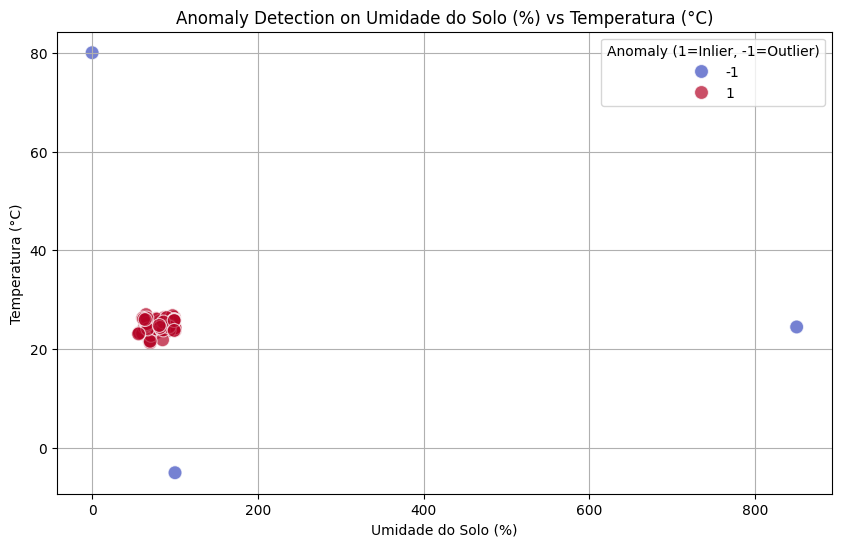

In [63]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.scatterplot(x='Umidade do Solo (%)', y='Temperatura (°C)', hue='anomaly', data=X_test, palette='coolwarm', s=100, alpha=0.7)
plt.title('Anomaly Detection on Umidade do Solo (%) vs Temperatura (°C)')
plt.xlabel('Umidade do Solo (%)')
plt.ylabel('Temperatura (°C)')
plt.legend(title='Anomaly (1=Inlier, -1=Outlier)')
plt.grid(True)
plt.show()

In [64]:
import joblib

# Exporta o modelo treinado para um arquivo
joblib.dump(iso_forest, 'modelo_isolation_forest.joblib')

['modelo_isolation_forest.joblib']


[Iniciando Investigação SHAP...]

🚨 RELATÓRIO DE ANOMALIA MULTIVARIADA 🚨
Valores lidos pelos sensores:
 - Temperatura (°C): 5.0
 - Umidade do Ar (%): 20.0
 - Umidade do Solo (%): 0
 - Luminosidade: 95.0

🔍 Investigação de Causa Raiz:
 -> Umidade do Solo (%): Peso na decisão = 1.9591
 -> Umidade do Ar (%): Peso na decisão = 1.7157
 -> Temperatura (°C): Peso na decisão = 1.6456
 -> Luminosidade: Peso na decisão = 0.4938

💡 CONCLUSÃO: O principal responsável por esta anomalia foi: **Umidade do Solo (%)**


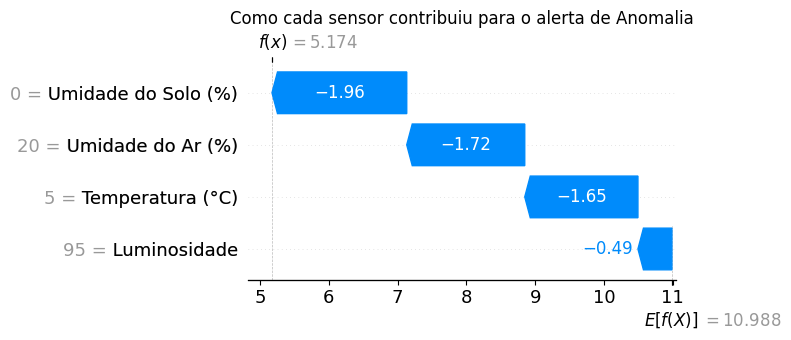

In [65]:
# Instale o SHAP se ainda não o fez: !pip install shap -q
import shap

def camada3_explicar_anomalia(modelo_if, dados_treino, leitura_anomala):
    """
    Camada 3: Recebe o modelo treinado e uma leitura específica (DataFrame de 1 linha)
    que foi classificada como anomalia, e retorna o culpado.
    """
    print("\n[Iniciando Investigação SHAP...]")

    # 1. Inicializar o Explainer do SHAP
    # O TreeExplainer é otimizado para árvores, como o Isolation Forest
    explainer = shap.TreeExplainer(modelo_if)

    # 2. Calcular os valores SHAP para a leitura anómala
    # shap_values contém a "força" que cada variável fez para empurrar o resultado para anomalia
    shap_values = explainer.shap_values(leitura_anomala)

    # 3. Organizar os resultados
    colunas = leitura_anomala.columns
    # Pegamos o valor absoluto porque queremos a magnitude da culpa (seja para mais ou para menos)
    importancia = pd.Series(np.abs(shap_values[0]), index=colunas).sort_values(ascending=False)

    print("\n==================================================")
    print("🚨 RELATÓRIO DE ANOMALIA MULTIVARIADA 🚨")
    print("==================================================")
    print("Valores lidos pelos sensores:")
    for col in colunas:
        print(f" - {col}: {leitura_anomala[col].values[0]}")

    print("\n🔍 Investigação de Causa Raiz:")
    for sensor, peso in importancia.items():
        print(f" -> {sensor}: Peso na decisão = {peso:.4f}")

    sensor_culpado = importancia.index[0]
    print(f"\n💡 CONCLUSÃO: O principal responsável por esta anomalia foi: **{sensor_culpado}**")
    print("==================================================")

    # 4. Gerar o Gráfico Waterfall do SHAP (Excelente para visualização)
    # Cria um objeto Explanation que o gráfico waterfall precisa
    # (Nota: o explainer.expected_value é a pontuação base média do modelo)
    exp = shap.Explanation(values=shap_values[0],
                           base_values=explainer.expected_value,
                           data=leitura_anomala.iloc[0].values,
                           feature_names=colunas)

    plt.figure(figsize=(10, 5))
    shap.plots.waterfall(exp, show=False)
    plt.title("Como cada sensor contribuiu para o alerta de Anomalia")
    plt.tight_layout()
    plt.show()

# --- Testando a Camada 3 ---
# Assumindo que 'iso_forest' é o seu modelo treinado e 'X_train' os dados de treino.
# Vamos simular um dado que passou pela Camada 1, mas que é um ambiente muito bizarro (frio extremo, mas muito luminoso e seco)
nova_leitura = pd.DataFrame({
    'Temperatura (°C)': [5.0],
    'Umidade do Ar (%)': [20.0],
    'Umidade do Solo (%)': [0],
    'Luminosidade': [95.0]
})

# A Camada 2 classifica:
previsao = iso_forest.predict(nova_leitura)

if previsao[0] == -1:
    # Se for anomalia, disparamos a Camada 3!
    camada3_explicar_anomalia(iso_forest, X_train, nova_leitura)
else:
    print("O ambiente está normal. Sem alertas.")